# V22: conditional mirror correction failed

One fixed rule preserves all H60 tie probabilities and off-route predictions,
then mixes conditional A/B probabilities on at most 5% of short uncertain rows.
**Original data overlaps training and was previously inspected; this is not CV.**
The information gate failed. No alternative grid, new inference, GPU or official
submission. [Protocol](../docs/SPAN_022_PLAN.md) · [Report](../docs/SPAN_022_RESULTS.md).

,model,log_loss,accuracy,brier
0,H60,0.652988,0.751953,0.365412
1,Conditional correction,0.654043,0.751953,0.366035


Selected / eligible / total: 25 229 512
Token work used / budget: 2391.0 16950.850000000002
Loss reduction: -0.0010548361022183462 ; paired group95: [-0.002035341889710561, -0.0001269630926192671]
Decision: stop_conditional_correction ; official eligible: False
CPU elapsed seconds: 0.09179609292186797 ; GPU / inference / network: 0 0 0


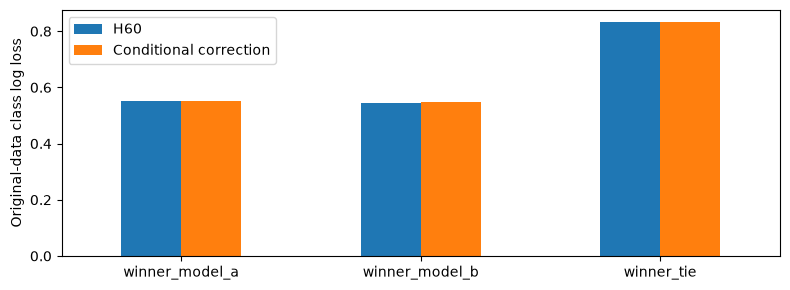

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
r=json.loads((REPO/'results/span_022/conditional_screen.json').read_text())
models={'H60':r['comparison']['baseline'],'Conditional correction':r['comparison']['candidate']}
display(pd.DataFrame([{'model':k,'log_loss':v['log_loss'],'accuracy':v['accuracy'],'brier':v['brier']} for k,v in models.items()]))
print('Selected / eligible / total:',r['budget']['selected_rows'],r['budget']['eligible_rows'],r['rows'])
print('Token work used / budget:',r['budget']['used_tokens'],r['budget']['token_budget'])
print('Loss reduction:',r['comparison']['loss_reduction'],'; paired group95:',r['comparison']['paired_group95'])
print('Decision:',r['decision'],'; official eligible:',r['official_submission_eligible'])
print('CPU elapsed seconds:',r['elapsed_cpu_seconds'],'; GPU / inference / network:',r['new_gpu_executions'],r['new_inference_executions'],r['network_calls'])
classes=['winner_model_a','winner_model_b','winner_tie']
pd.DataFrame({k:v['class_log_loss'] for k,v in models.items()}).loc[classes].plot.bar(figsize=(8,3),ylabel='Original-data class log loss',rot=0)
plt.tight_layout();plt.show()

In [2]:
import hashlib
import numpy as np
ROOT=Path.home()/'database/llm_classification_finetuning'
for name,digest in r['output_sha256'].items():
 assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==digest
a=np.load(ROOT/'runs/span_022/conditional_uniform_analysis.npz')
print('Saved array fields:',a.files)
assert all(r[k] for k in ['tie_probabilities_exact','offroute_predictions_exact','ab_mass_preserved','all_true_tie_loss_differences_zero'])
assert r['comparison']['loss_reduction']<=.001 and not r['original_information_gate_passed']
assert r['decision']=='stop_conditional_correction'
assert not r['later_comparison_complete'] and not r['hidden_score_forecast']
print('Preservation and failed-gate checks passed. Stop this correction; no rescue grid.')

Saved array fields: ['ids', 'labels', 'groups', 'baseline', 'candidate', 'mirror', 'selected_indices', 'route_scores', 'paired_loss_reduction']
Preservation and failed-gate checks passed. Stop this correction; no rescue grid.
